# Évaluation finale sur le test

Le modèle retenu (LightGBM optimisé) est évalué une seule fois sur le jeu de test : 141 matchs qui n'ont servi ni à l'entraînement, ni au choix des variables, ni au réglage des hyperparamètres.

Points examinés :
1. performance sur le test, comparée aux références simples et à l'estimation par validation croisée ;
2. incertitude des scores (bootstrap par match) ;
3. calibration des probabilités ;
4. performance selon le moment du round et selon la carte ;
5. évolution de la probabilité au cours de quelques rounds.

## 0. Imports, modèle et données

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import json
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix

from src.config import ROOT_DIR, SEED, TARGET
from src.rounds import load_processed
from src.baselines import AliveRule, FrequencyTable
from src.evaluation import compute_metrics
from src.final_eval import bootstrap_by_group, calibration_table, expected_calibration_error, metrics_by
from src.train import MODEL_PATH, load_model, train_final_model
from src.tuning import load_best_params
from src.viz import COLOR_CT, COLOR_T, COLOR_TEXT, COLOR_TEXT_MUTED, save_fig, set_style

set_style()
df = load_processed()
train = df[df["split"] == "train"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)

if MODEL_PATH.exists():
    model = load_model()
else:
    model = train_final_model(train, load_best_params())
print(f"Test : {len(test):,} lignes, {test['round_id'].nunique():,} rounds, {test['match_id'].nunique()} matchs")

Test : 24,978 lignes, 3,768 rounds, 141 matchs


## 1. Score sur le test

Les références sont ajustées sur le train uniquement, comme le modèle.

In [2]:
y_test = test[TARGET].to_numpy()
test["proba"] = model.predict_proba(test)[:, 1]

references = {
    "Classe majoritaire": DummyClassifier(strategy="prior"),
    "Règle : joueurs vivants + bombe": AliveRule(bomb_tiebreak=True),
    "Table : écart de joueurs × bombe": FrequencyTable(use_bomb=True),
}
rows = []
for name, est in references.items():
    est.fit(train, train[TARGET])
    rows.append({"modèle": name, **compute_metrics(y_test, est.predict_proba(test)[:, 1])})
rows.append({"modèle": "LightGBM optimisé", **compute_metrics(y_test, test["proba"].to_numpy())})
test_scores = pd.DataFrame(rows)

cv = pd.read_csv(ROOT_DIR / "reports" / "cv_modeles.csv").set_index("configuration")
cv_best = cv.loc["LightGBM optimisé", ["accuracy", "roc_auc", "log_loss", "brier"]]
lgbm_test = test_scores.set_index("modèle").loc["LightGBM optimisé"]
cv_vs_test = pd.DataFrame({"validation croisée (train)": cv_best, "test": lgbm_test[cv_best.index]})

display(test_scores.style.format({"accuracy": "{:.2%}", "roc_auc": "{:.4f}", "log_loss": "{:.4f}",
                                  "brier": "{:.4f}"}).hide(axis="index"))
cv_vs_test.style.format("{:.4f}")

modèle,accuracy,roc_auc,log_loss,brier
Classe majoritaire,50.37%,0.5000,0.6932,0.2500
Règle : joueurs vivants + bombe,63.90%,0.6413,4.9874,0.3610
Table : écart de joueurs × bombe,63.87%,0.7147,0.5712,0.2006
LightGBM optimisé,70.84%,0.8058,0.5128,0.1760


,validation croisée (train),test
accuracy,0.7113,0.7084
roc_auc,0.8084,0.8058
log_loss,0.5122,0.5128
brier,0.1755,0.1760


La règle fixe donne des probabilités de 0 ou 1 : sa log loss n'est pas comparable (voir `05_baselines.ipynb`). Le second tableau compare le score du test à l'estimation obtenue par validation croisée : des valeurs proches indiquent que l'estimation était fiable et que le modèle n'a pas été sur-ajusté à la procédure de sélection.

## 2. Incertitude des scores

Le test contient 141 matchs : un autre échantillon de matchs donnerait un score un peu différent. L'intervalle de confiance à 95 % est estimé par bootstrap, en tirant des **matchs entiers** avec remise (1 000 tirages), car les snapshots d'un même match ne sont pas indépendants.

In [3]:
ci = bootstrap_by_group(y_test, test["proba"], test["match_id"], n_boot=1000)
ci.style.format("{:.4f}")

,valeur,borne_basse,borne_haute
accuracy,0.7084,0.6966,0.7202
roc_auc,0.8058,0.7947,0.8162
log_loss,0.5128,0.5021,0.5236
brier,0.1760,0.1716,0.1805


## 3. Matrice de confusion

Seuil de décision : 50 %.

In [4]:
pred = (test["proba"] >= 0.5).astype(int)
cm = pd.DataFrame(confusion_matrix(y_test, pred, normalize="true"),
                  index=["vrai gagnant : CT", "vrai gagnant : T"],
                  columns=["prédit : CT", "prédit : T"])
cm.style.format("{:.1%}")

,prédit : CT,prédit : T
vrai gagnant : CT,73.5%,26.5%
vrai gagnant : T,31.7%,68.3%


## 4. Calibration des probabilités

Le modèle sert à estimer une probabilité de victoire. On vérifie qu'elle est fiable : parmi toutes les situations où le modèle annonce environ 70 %, les T doivent gagner environ 70 % du temps. Sur le graphique, un modèle parfaitement calibré suit la diagonale.

L'ECE (*expected calibration error*) résume l'écart moyen entre probabilité annoncée et fréquence observée, pondéré par le nombre de lignes de chaque tranche.

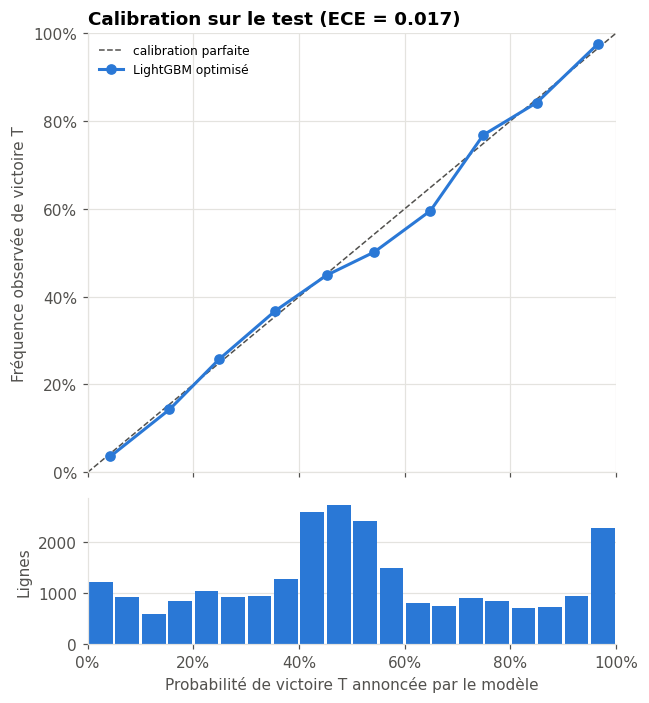

bin,proba_moyenne,frequence_observee,n
"(-0.001, 0.1]",4.3%,3.6%,"2,156"
"(0.1, 0.2]",15.5%,14.3%,"1,433"
"(0.2, 0.3]",24.9%,25.8%,"1,978"
"(0.3, 0.4]",35.5%,36.8%,"2,216"
"(0.4, 0.5]",45.2%,44.9%,"5,314"
"(0.5, 0.6]",54.3%,50.2%,"3,914"
"(0.6, 0.7]",64.9%,59.6%,"1,558"
"(0.7, 0.8]",74.9%,76.8%,"1,750"
"(0.8, 0.9]",85.0%,84.2%,"1,443"
"(0.9, 1.0]",96.6%,97.6%,"3,216"


In [5]:
calib = calibration_table(y_test, test["proba"], n_bins=10)
ece = expected_calibration_error(y_test, test["proba"], n_bins=10)

fig, (ax, ax_hist) = plt.subplots(2, 1, figsize=(6, 6.5), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 1]})
ax.plot([0, 1], [0, 1], color=COLOR_TEXT_MUTED, linestyle="--", linewidth=1, label="calibration parfaite")
ax.plot(calib["proba_moyenne"], calib["frequence_observee"], color=COLOR_CT, linewidth=2,
        marker="o", markersize=6, label="LightGBM optimisé")
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylabel("Fréquence observée de victoire T")
ax.set_title(f"Calibration sur le test (ECE = {ece:.3f})")
ax.legend(loc="upper left", fontsize=8)

ax_hist.hist(test["proba"], bins=20, range=(0, 1), color=COLOR_CT, rwidth=0.9)
ax_hist.set_xlim(0, 1)
ax_hist.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax_hist.set_xlabel("Probabilité de victoire T annoncée par le modèle")
ax_hist.set_ylabel("Lignes")
ax_hist.grid(axis="x", visible=False)
plt.tight_layout()
save_fig(fig, "15_calibration_test")
plt.show()

calib.style.format({"proba_moyenne": "{:.1%}", "frequence_observee": "{:.1%}", "n": "{:,}"}).hide(axis="index")

L'histogramme du bas montre combien de lignes tombent dans chaque tranche : les tranches peu remplies ont une fréquence observée moins précise.

## 5. Performance selon la situation de jeu

In [6]:
test["phase"] = pd.cut(test["time_left"], [-1, 40, 80, 120, 160, 176],
                       labels=["moins de 40 s", "40 à 80 s", "80 à 120 s", "120 à 160 s", "plus de 160 s"])
by_phase = metrics_by(test, TARGET, "proba", "phase").iloc[::-1]
by_phase["part des lignes"] = by_phase["n"] / by_phase["n"].sum()
by_phase.style.format({"n": "{:,}", "accuracy": "{:.1%}", "roc_auc": "{:.3f}", "log_loss": "{:.3f}",
                       "brier": "{:.3f}", "part des lignes": "{:.0%}"}).hide(axis="index")

groupe,n,accuracy,roc_auc,log_loss,brier,part des lignes
plus de 160 s,"6,674",60.5%,0.667,0.638,0.225,27%
120 à 160 s,162,69.8%,0.719,0.613,0.214,1%
80 à 120 s,"7,327",66.7%,0.750,0.573,0.198,29%
40 à 80 s,"5,718",74.6%,0.840,0.482,0.162,23%
moins de 40 s,"5,097",86.1%,0.943,0.294,0.095,20%


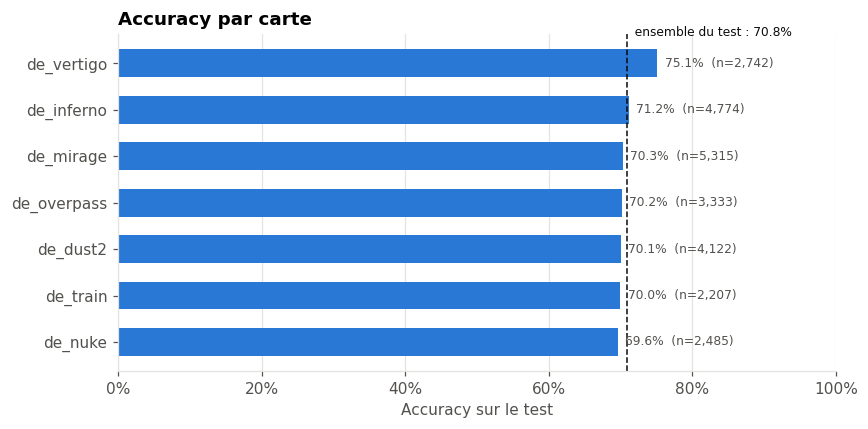

In [7]:
by_map = metrics_by(test, TARGET, "proba", "map").sort_values("accuracy")

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(by_map["groupe"].astype(str), by_map["accuracy"], color=COLOR_CT, height=0.6)
for y, (acc, n) in enumerate(zip(by_map["accuracy"], by_map["n"])):
    ax.text(acc + 0.01, y, f"{acc:.1%}  (n={n:,})", va="center", fontsize=8, color=COLOR_TEXT_MUTED)
overall = compute_metrics(y_test, test["proba"].to_numpy())["accuracy"]
ax.axvline(overall, color=COLOR_TEXT, linestyle="--", linewidth=1)
ax.text(overall, len(by_map) - 0.4, f"  ensemble du test : {overall:.1%}", fontsize=8, color=COLOR_TEXT)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Accuracy sur le test")
ax.set_title("Accuracy par carte")
ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig(fig, "16_accuracy_par_carte")
plt.show()

Les cartes avec peu de lignes dans le test ont une accuracy moins précise : l'effectif `n` est indiqué à côté de chaque barre.

## 6. La probabilité au cours d'un round

Pour trois rounds disputés du test, on suit la probabilité de victoire T estimée à chaque snapshot : le round gagné par les T où la probabilité a le plus varié, la même chose pour les CT, et le round où la probabilité a le plus souvent franchi 50 %. Les rounds de plus de 12 snapshots (pauses, chrono bloqué) sont exclus.

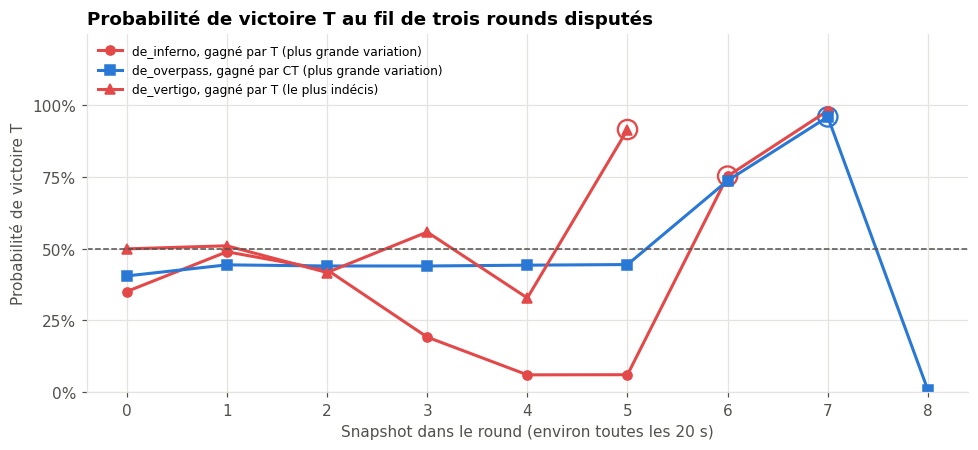

In [8]:
rounds = test.groupby("round_id").agg(
    winner=("round_winner", lambda w: str(w.iloc[0])), n=("proba", "size"),
    swing=("proba", lambda p: p.max() - p.min()),
    crossings=("proba", lambda p: int((np.diff(np.sign(p.to_numpy() - 0.5)) != 0).sum())))
rounds = rounds[rounds["n"].between(5, 12)]  # au-delà de 12 snapshots : pauses (chrono bloqué)
chosen = {
    "plus grande variation": rounds[rounds["winner"] == "T"]["swing"].idxmax(),
    "plus grande variation ": rounds[rounds["winner"] == "CT"]["swing"].idxmax(),
}
rest = rounds.drop(index=list(chosen.values()))
chosen["le plus indécis"] = rest.sort_values(["crossings", "swing"], ascending=False).index[0]

fig, ax = plt.subplots(figsize=(9, 4.2))
for (label, rid), marker in zip(chosen.items(), ["o", "s", "^"]):
    r = test[test["round_id"] == rid].sort_values("snapshot_idx")
    winner = r["round_winner"].astype(str).iloc[0]
    color = COLOR_T if winner == "T" else COLOR_CT
    x = np.arange(len(r))
    ax.plot(x, r["proba"], color=color, linewidth=2, marker=marker, markersize=6,
            label=f"{r['map'].iloc[0]}, gagné par {winner} ({label.strip()})")
    bomb = r["bomb_planted"].astype(bool).to_numpy()
    if bomb.any():
        first = int(np.argmax(bomb))
        ax.scatter(first, r["proba"].iloc[first], s=160, facecolors="none", edgecolors=color, linewidths=1.5)
ax.axhline(0.5, color=COLOR_TEXT_MUTED, linestyle="--", linewidth=1)
ax.set_ylim(0, 1.25)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Snapshot dans le round (environ toutes les 20 s)")
ax.set_ylabel("Probabilité de victoire T")
ax.set_title("Probabilité de victoire T au fil de trois rounds disputés")
ax.legend(loc="upper left", fontsize=8, ncol=1)
plt.tight_layout()
save_fig(fig, "17_rounds_exemples")
plt.show()

Un cercle marque le premier snapshot où la bombe est posée. Couleur : rouge si le round a été gagné par les T, bleu s'il a été gagné par les CT.

## 7. Résumé des résultats

In [9]:
best_ref = test_scores[test_scores["modèle"] != "LightGBM optimisé"].set_index("modèle")["accuracy"]
results = {
    "test_rows": int(len(test)), "test_matches": int(test["match_id"].nunique()),
    "metrics": {k: float(v) for k, v in ci["valeur"].items()},
    "ci95_low": {k: float(v) for k, v in ci["borne_basse"].items()},
    "ci95_high": {k: float(v) for k, v in ci["borne_haute"].items()},
    "ece": ece,
}
(ROOT_DIR / "reports" / "test_metrics.json").write_text(json.dumps(results, indent=2), encoding="utf-8")

print("=== Résumé ===")
print(f"Test : {len(test):,} lignes, {test['match_id'].nunique()} matchs")
for m in ["accuracy", "roc_auc", "log_loss", "brier"]:
    print(f"{m:<9}: test {ci.loc[m, 'valeur']:.4f}  [IC 95 % {ci.loc[m, 'borne_basse']:.4f} ; "
          f"{ci.loc[m, 'borne_haute']:.4f}]  | validation croisée {cv_best[m]:.4f}")
print(f"Meilleure référence sur le test : {best_ref.idxmax()} ({best_ref.max():.2%})")
print(f"ECE : {ece:.4f}")
print(f"Taux de vrais positifs T / vrais négatifs CT : {cm.iloc[1, 1]:.1%} / {cm.iloc[0, 0]:.1%}")
print("Accuracy par phase :", ", ".join(f"{g} {a:.1%}" for g, a in zip(by_phase['groupe'], by_phase['accuracy'])))
print("Accuracy par carte :", ", ".join(f"{g} {a:.1%} (n={n})" for g, a, n in
                                         zip(by_map['groupe'], by_map['accuracy'], by_map['n'])))

=== Résumé ===
Test : 24,978 lignes, 141 matchs
accuracy : test 0.7084  [IC 95 % 0.6966 ; 0.7202]  | validation croisée 0.7113
roc_auc  : test 0.8058  [IC 95 % 0.7947 ; 0.8162]  | validation croisée 0.8084
log_loss : test 0.5128  [IC 95 % 0.5021 ; 0.5236]  | validation croisée 0.5122
brier    : test 0.1760  [IC 95 % 0.1716 ; 0.1805]  | validation croisée 0.1755
Meilleure référence sur le test : Règle : joueurs vivants + bombe (63.90%)
ECE : 0.0166
Taux de vrais positifs T / vrais négatifs CT : 68.3% / 73.5%
Accuracy par phase : plus de 160 s 60.5%, 120 à 160 s 69.8%, 80 à 120 s 66.7%, 40 à 80 s 74.6%, moins de 40 s 86.1%
Accuracy par carte : de_nuke 69.6% (n=2485), de_train 70.0% (n=2207), de_dust2 70.1% (n=4122), de_overpass 70.2% (n=3333), de_mirage 70.3% (n=5315), de_inferno 71.2% (n=4774), de_vertigo 75.1% (n=2742)


## Conclusion

**Performance sur le test** (141 matchs, 24 978 snapshots, jamais utilisés auparavant) :

| Métrique | Test | IC 95 % | Validation croisée |
| --- | --- | --- | --- |
| Accuracy | 70,84 % | 69,66 – 72,02 % | 71,13 % |
| ROC-AUC | 0,8058 | 0,7947 – 0,8162 | 0,8084 |
| Log loss | 0,5128 | 0,5021 – 0,5236 | 0,5122 |
| Brier | 0,1760 | 0,1716 – 0,1805 | 0,1755 |

Les scores du test sont très proches de l'estimation par validation croisée, et celle-ci tombe dans l'intervalle de confiance du test pour chaque métrique. Le protocole (découpage par match, sélection uniquement sur le train) a donc donné une estimation fiable de la performance réelle. Le modèle dépasse la meilleure règle simple de près de 7 points sur le test (70,8 % contre 63,9 %).

**Calibration :** l'ECE est de 0,017. Quand le modèle annonce une probabilité, la fréquence de victoire observée en est très proche ; aucune recalibration n'est nécessaire. C'est le résultat le plus important pour l'usage visé : estimer une probabilité de victoire, pas seulement désigner un vainqueur.

**Erreurs :** le modèle reconnaît 68,3 % des victoires T et 73,5 % des victoires CT. Comme en validation croisée, la précision dépend surtout du moment du round : 60,5 % en début de round (plus de 160 s restantes), 86,1 % dans les 40 dernières secondes. Les cartes donnent des résultats homogènes (69,6 % à 71,2 %), sauf de_vertigo (75,1 %).

**Exemples de rounds :** les trajectoires montrent que le modèle réagit aux événements du jeu. Sur de_inferno, la probabilité des T tombe à 6 %, puis remonte à 98 % après la pose de la bombe, et les T gagnent. Sur de_overpass, elle atteint 96 % avec la bombe posée, mais les CT désamorcent et gagnent. Une probabilité élevée n'est pas une certitude, ce qui est cohérent avec un modèle bien calibré.